# 02 · Cleaning and EDA

Exploration and plots only; the logic is in `f1strat.clean`.

- `clean_laps` labels each lap with the first `exclude_reason` (or null if it is
  usable for the degradation model) and adds `gap_ahead_s` and `dirty_air`.
- `pit_loss` gives the median green-flag pit lane loss per circuit.

Raw lap times may stay flat or fall as tyre age rises because fuel burns off.
That is expected and is separated out in Phase 3, so it is not corrected here.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from f1strat.clean import EXCLUDE_REASONS, clean_laps, pit_loss
from f1strat.data import load_season

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Validated categorical palette (dataviz validator, light surface). Hard is blue
# rather than F1's white so it shows on a light background.
COMPOUND_COLORS = {"SOFT": "#d9342b", "MEDIUM": "#eda100", "HARD": "#2a78d6"}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "savefig.dpi": 150, "savefig.bbox": "tight",
})

laps = load_season(2022)
race = load_season(2022, table="race")
cleaned = clean_laps(laps)
clean = cleaned[cleaned["exclude_reason"].isna()].assign(
    lap_s=lambda d: d["LapTime"].dt.total_seconds()
)
print(f"{len(cleaned):,} laps, {len(clean):,} clean ({len(clean) / len(cleaned):.0%})")
print(f"dirty air on {clean['dirty_air'].mean():.0%} of clean laps")

23,577 laps, 16,899 clean (72%)
dirty air on 21% of clean laps


## Clean lap time vs tyre age: Bahrain, Spain, Hungary

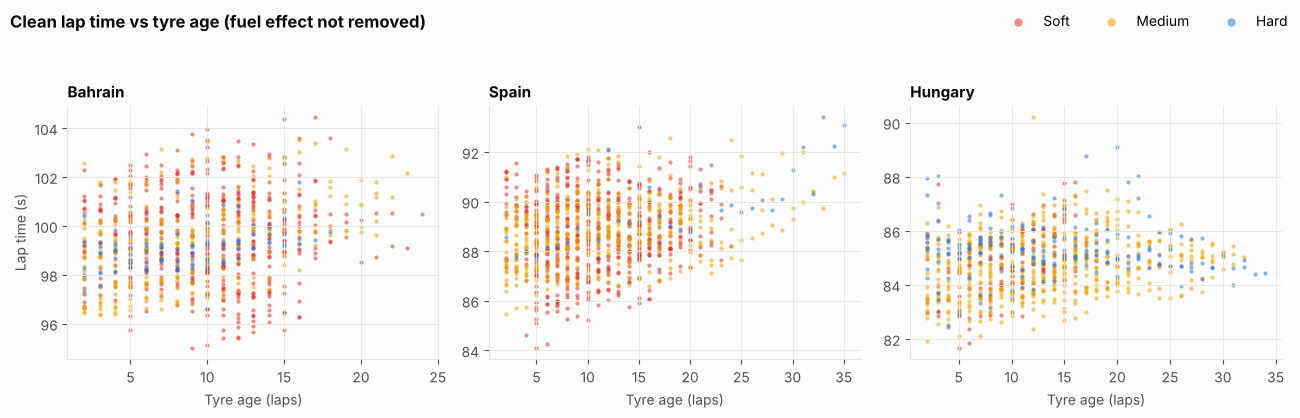

In [2]:
def deg_scatter(ax, df, title):
    for compound, color in COMPOUND_COLORS.items():
        d = df[df["Compound"] == compound]
        if d.empty:
            continue
        ax.scatter(d["TyreLife"], d["lap_s"], s=9, color=color, alpha=0.55,
                   linewidths=0, label=compound.title())
    ax.set_title(title, loc="left")
    ax.set_xlabel("Tyre age (laps)")

events = [(1, "Bahrain"), (6, "Spain"), (13, "Hungary")]
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=False)
for ax, (rnd, name) in zip(axes, events):
    deg_scatter(ax, clean[clean["RoundNumber"] == rnd], name)
axes[0].set_ylabel("Lap time (s)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncol=3, frameon=False, markerscale=2)
fig.suptitle("Clean lap time vs tyre age (fuel effect not removed)", x=0.01, ha="left",
             fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIG_DIR / "deg_bahrain_spain_hungary.png")
plt.show()

## All 22 races, same view

A sanity check for incoherent stints or wild outliers. Each panel has its own
y-axis.

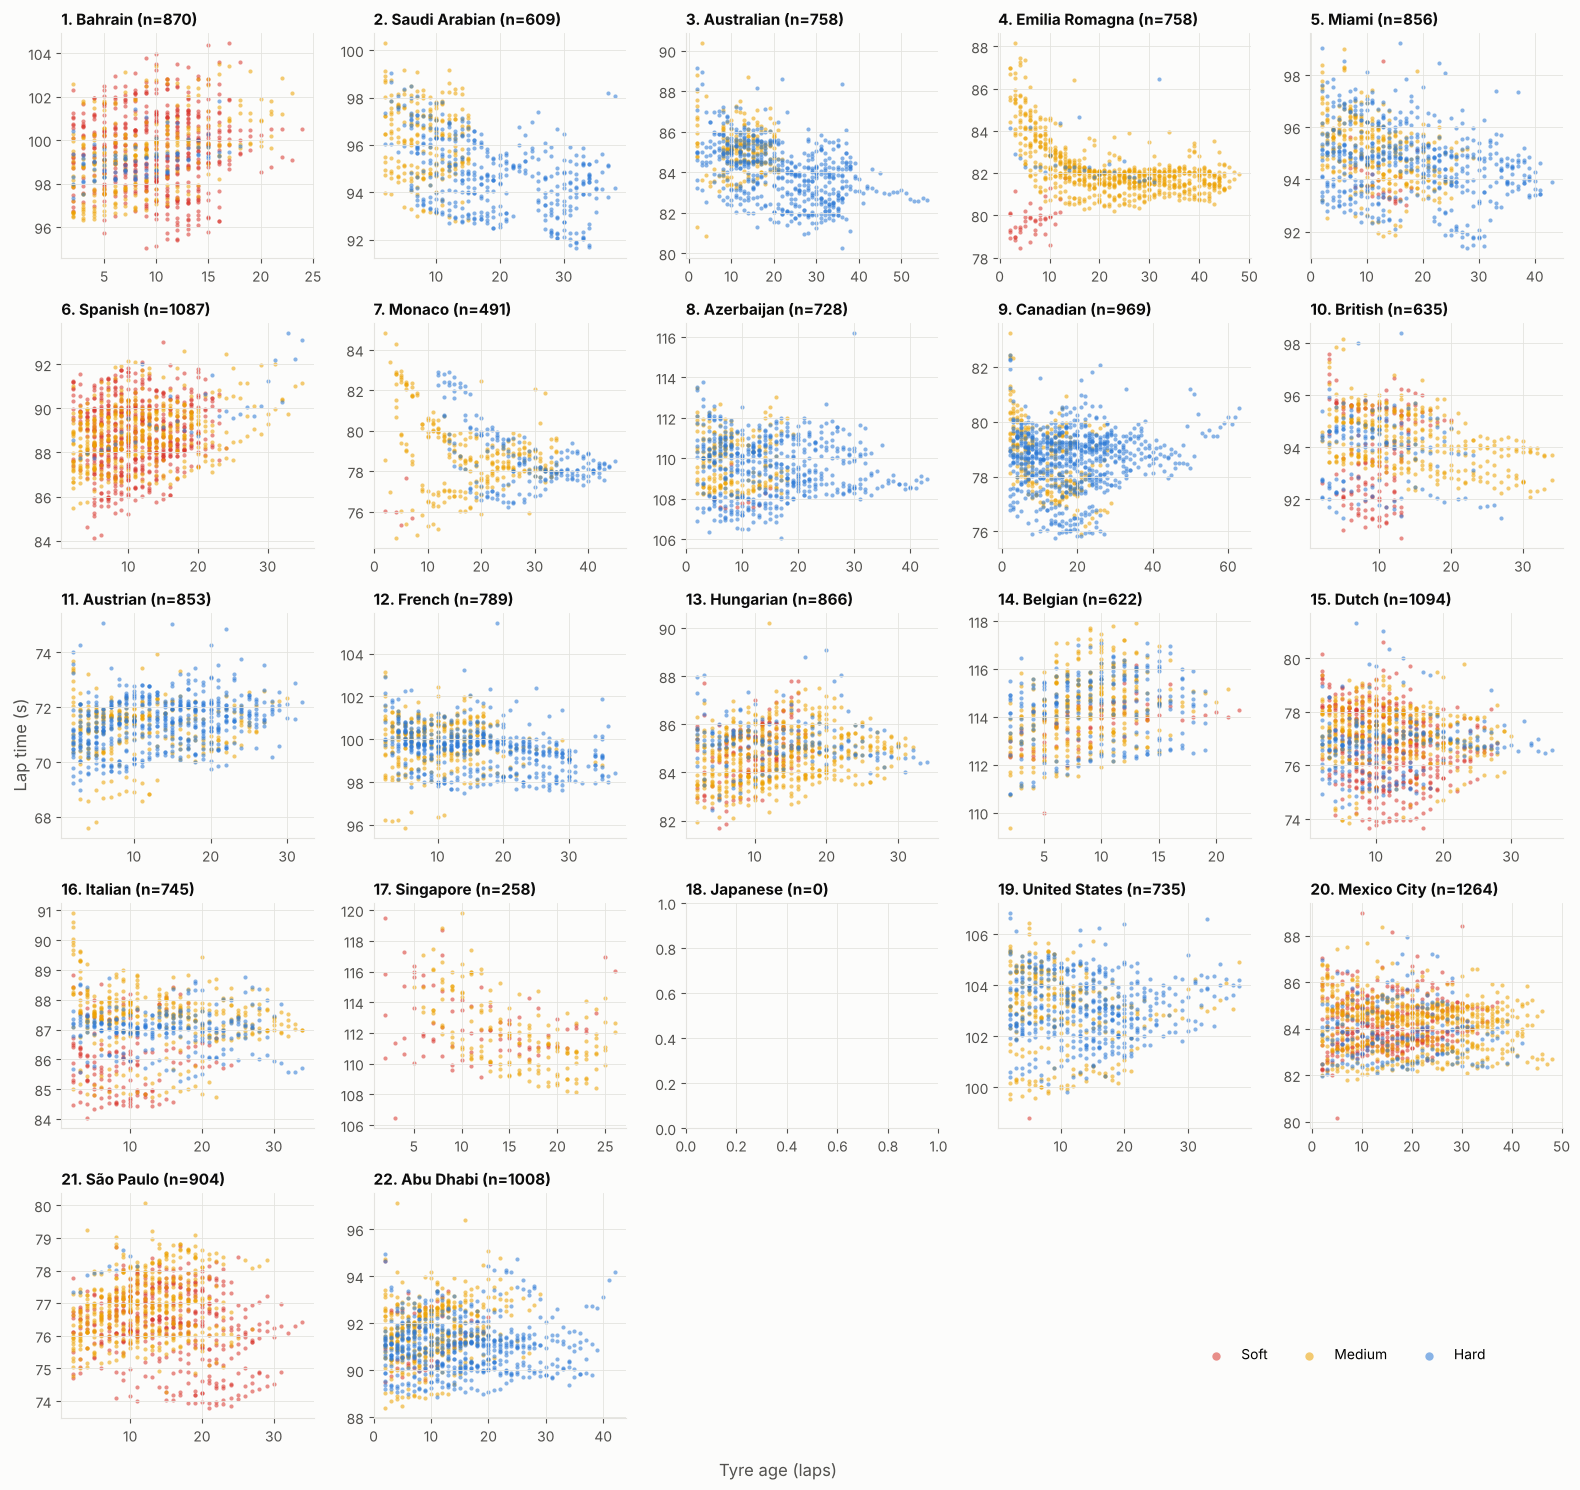

In [3]:
rounds = race.groupby("RoundNumber")["EventName"].first()
fig, axes = plt.subplots(5, 5, figsize=(16, 15))
for ax, (rnd, name) in zip(axes.flat, rounds.items()):
    d = clean[clean["RoundNumber"] == rnd]
    deg_scatter(ax, d, f"{rnd}. {name.replace(' Grand Prix', '')} (n={len(d)})")
    ax.set_xlabel("")
for ax in axes.flat[len(rounds):]:
    ax.set_visible(False)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower right", ncol=3, frameon=False, markerscale=2,
           bbox_to_anchor=(0.95, 0.08))
fig.supxlabel("Tyre age (laps)", color=INK_2)
fig.supylabel("Lap time (s)", color=INK_2)
fig.tight_layout()
fig.savefig(FIG_DIR / "deg_all_races.png")
plt.show()

## Laps per exclude reason per race

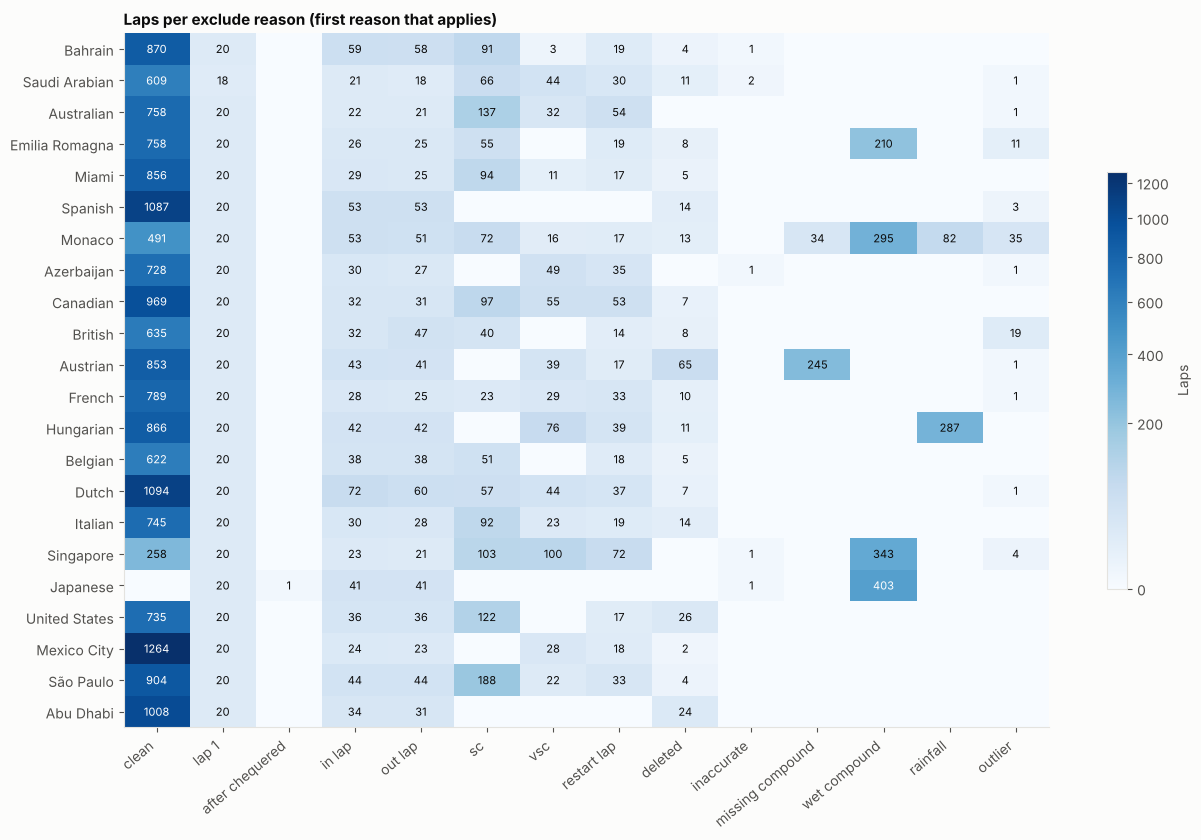

reason,clean,lap_1,after_chequered,in_lap,out_lap,sc,vsc,restart_lap,deleted,inaccurate,missing_compound,wet_compound,rainfall,outlier
EventName,,,,,,,,,,,,,,
Bahrain Grand Prix,870,20,0,59,58,91,3,19,4,1,0,0,0,0
Saudi Arabian Grand Prix,609,18,0,21,18,66,44,30,11,2,0,0,0,1
Australian Grand Prix,758,20,0,22,21,137,32,54,0,0,0,0,0,1
Emilia Romagna Grand Prix,758,20,0,26,25,55,0,19,8,0,0,210,0,11
Miami Grand Prix,856,20,0,29,25,94,11,17,5,0,0,0,0,0
Spanish Grand Prix,1087,20,0,53,53,0,0,0,14,0,0,0,0,3
Monaco Grand Prix,491,20,0,53,51,72,16,17,13,0,34,295,82,35
Azerbaijan Grand Prix,728,20,0,30,27,0,49,35,0,1,0,0,0,1
Canadian Grand Prix,969,20,0,32,31,97,55,53,7,0,0,0,0,0


In [4]:
counts = (
    cleaned.assign(reason=cleaned["exclude_reason"].astype("object").fillna("clean"))
    .pivot_table(index="EventName", columns="reason", values="LapNumber",
                 aggfunc="size", fill_value=0)
)
order = ["clean"] + [r for r in EXCLUDE_REASONS if r in counts.columns]
counts = counts[order].loc[rounds.values]

fig, ax = plt.subplots(figsize=(13, 8.5))
im = ax.imshow(counts.to_numpy(), cmap="Blues", aspect="auto",
               norm=plt.matplotlib.colors.PowerNorm(0.5))
ax.set_xticks(range(len(order)), [o.replace("_", " ") for o in order], rotation=40, ha="right")
ax.set_yticks(range(len(counts)), [e.replace(" Grand Prix", "") for e in counts.index])
ax.grid(False)
vmax = counts.to_numpy().max()
for i in range(counts.shape[0]):
    for j in range(counts.shape[1]):
        v = counts.iat[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=8,
                    color="white" if v > 0.3 * vmax else INK)
ax.set_title("Laps per exclude reason (first reason that applies)", loc="left")
fig.colorbar(im, ax=ax, shrink=0.6, label="Laps")
fig.tight_layout()
fig.savefig(FIG_DIR / "exclude_reasons.png")
plt.show()
counts

## Green-flag pit lane loss per circuit

Per stop: (in lap + out lap) minus 2 × the driver's median clean lap. Dot is
the median over green-flag stops; bar is the interquartile range.

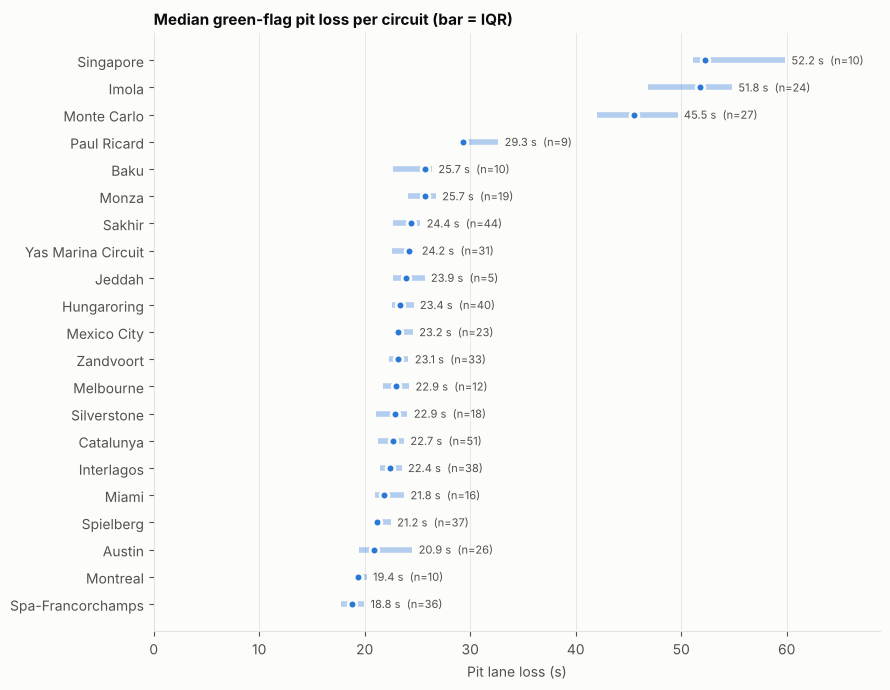

no green-flag estimate: ['Japanese Grand Prix']


,RoundNumber,EventName,Circuit,pit_loss_s,q25_s,q75_s,n_stops
13,14,Belgian Grand Prix,Spa-Francorchamps,18.8355,17.79450,19.94900,36
8,9,Canadian Grand Prix,Montreal,19.3895,19.02150,20.18325,10
17,19,United States Grand Prix,Austin,20.9035,19.43575,24.51225,26
10,11,Austrian Grand Prix,Spielberg,21.1630,20.78000,22.47200,37
4,5,Miami Grand Prix,Miami,21.8450,20.93550,23.73875,16
19,21,São Paulo Grand Prix,Interlagos,22.4125,21.47600,23.50075,38
5,6,Spanish Grand Prix,Catalunya,22.6630,21.28450,23.72650,51
9,10,British Grand Prix,Silverstone,22.8670,21.08175,24.05475,18
2,3,Australian Grand Prix,Melbourne,22.9490,21.76300,24.21125,12
14,15,Dutch Grand Prix,Zandvoort,23.1440,22.29800,24.15000,33


In [5]:
pit = pd.read_parquet("../data/processed/2022/pit_loss.parquet")
pit_check = pit_loss(cleaned, race)
assert np.allclose(pit["pit_loss_s"], pit_check["pit_loss_s"]), "saved table is stale"

p = pit.sort_values("pit_loss_s")
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(p))
ax.hlines(y, p["q25_s"], p["q75_s"], color="#2a78d6", alpha=0.35, linewidth=4)
ax.scatter(p["pit_loss_s"], y, color="#2a78d6", s=40, zorder=3,
           edgecolors=SURFACE, linewidths=2)
for yi, (_, r) in zip(y, p.iterrows()):
    ax.text(r["q75_s"] + 0.6, yi, f"{r['pit_loss_s']:.1f} s  (n={r['n_stops']})",
            va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, p["Circuit"])
ax.set_xlabel("Pit lane loss (s)")
ax.set_xlim(0, p["q75_s"].max() + 9)
ax.grid(axis="y", visible=False)
ax.set_title("Median green-flag pit loss per circuit (bar = IQR)", loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "pit_loss.png")
plt.show()
missing = sorted(set(rounds.index) - set(pit["RoundNumber"]))
print("no green-flag estimate:", [rounds[r] for r in missing])
p